In [1]:
import pandas as pd
import numpy as np
import json 
import matplotlib.pyplot as plt 
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

In [2]:
results = pd.read_csv('./results_summary.csv')

### Training Diagnostics

Text(0, 0.5, 'Number of runs')

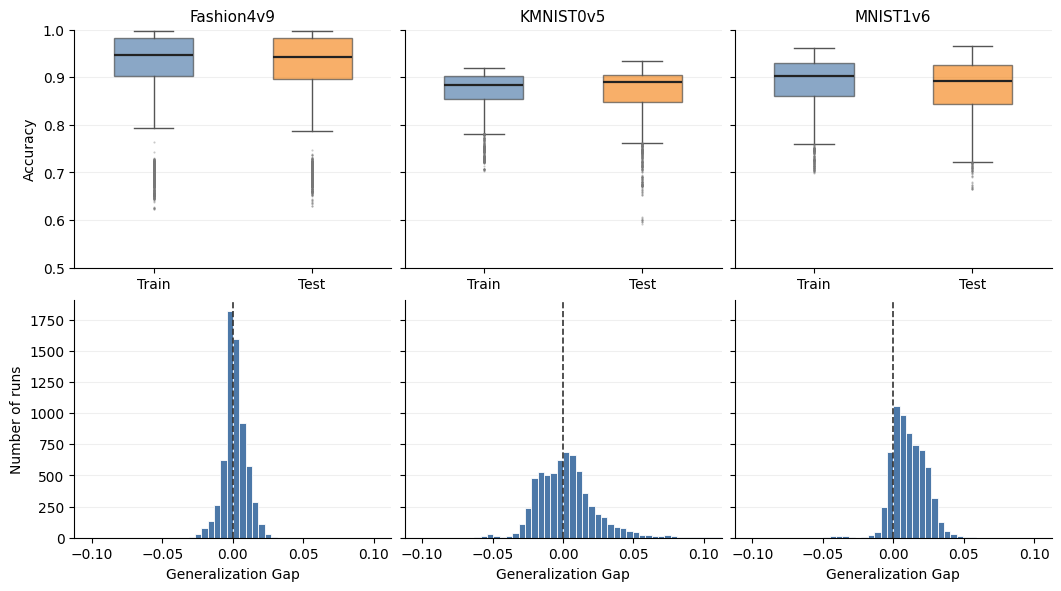

In [3]:
datasets = ['Fashion4v9', 'KMNIST0v5', 'MNIST1v6']
gap_col = 'Generalization Gap'
colors = ['#4C78A8', '#F58518']  # train, test

# One symmetric set of bin edges for all three datasets.
all_gaps = results[results['Dataset'].isin(datasets)][gap_col].to_numpy(dtype=float)
all_gaps = all_gaps[np.isfinite(all_gaps)]

n_side = 25          
width_step = 0.0001
max_abs = np.max(np.abs(all_gaps))
bin_width = max(width_step,
                np.ceil(max_abs / (n_side * width_step)) * width_step)
bin_edges = np.arange(-n_side, n_side + 1) * bin_width
x_limit = n_side * bin_width

fig, axes = plt.subplots(
    2, 3, figsize=(10.5, 5.8),
    sharey='row', layout='constrained'
)

for col, dataset in enumerate(datasets):
    subset = results.loc[results['Dataset'] == dataset]
    ax_box, ax_hist = axes[:, col]

    accuracy = [
        subset['train_acc'].dropna().to_numpy(),
        subset['test_acc'].dropna().to_numpy(),
    ]
    bp = ax_box.boxplot(
        accuracy, patch_artist=True, widths=0.5,
        medianprops={'color': '#222222', 'linewidth': 1.6},
        whiskerprops={'color': '#555555'},
        capprops={'color': '#555555'},
        flierprops={'marker': '.', 'markersize': 3,
                    'markerfacecolor': '#777777', 'markeredgecolor': 'none',
                    'alpha': 0.4},
    )
    for patch, color in zip(bp['boxes'], colors):
        patch.set(facecolor=color, alpha=0.65, edgecolor='#444444')

    ax_box.set_title(dataset, fontsize=11)
    ax_box.set_xticks([1, 2], ['Train', 'Test'])
    ax_box.set_ylim(0.5, 1)
    ax_box.grid(axis='y', alpha=0.2)
    ax_box.set_axisbelow(True)

    gaps = subset[gap_col].dropna().to_numpy(dtype=float)
    ax_hist.hist(gaps, bins=bin_edges, color='#4C78A8',
                 edgecolor='white', linewidth=0.6)
    ax_hist.axvline(0, color='#333333', linestyle='--', linewidth=1.2)
    ax_hist.set_xlim(-x_limit, x_limit)
    ax_hist.set_xlabel('Generalization Gap')
    ax_hist.grid(axis='y', alpha=0.2)
    ax_hist.set_axisbelow(True)

for ax in axes.flat:
    ax.spines[['top', 'right']].set_visible(False)

axes[0, 0].set_ylabel('Accuracy')
axes[1, 0].set_ylabel('Number of runs')

### SE Test

In [4]:
def plot_sign_error_cdf_bars(errors, subset_order=None, measure_order=None):
    """
    errors[subset][measure] = 1D array of sign errors, one per environment.
    Example subsets: "All", "Number of Qubits", "Ansatz", "Batch Size".
    """
    if subset_order is None:
        subset_order = list(errors)

    if measure_order is None:
        # Match the paper: order measures by mean sign error in "All".
        measure_order = sorted(
            errors["All"],
            key=lambda m: np.mean(errors["All"][m]),
        )

    n_measures = len(measure_order)
    thresholds = np.linspace(0, 1, 301)

    fig, axes = plt.subplots(
        len(subset_order), 1,
        figsize=(max(7, 0.85 * n_measures + 2),
         1.4 * len(subset_order) + 1.3),
        sharex=True, sharey=True,
        layout="constrained",
    )
    axes = np.atleast_1d(axes)

    for ax, subset in zip(axes, subset_order):
        cdf_image = np.full((len(thresholds), n_measures), np.nan)

        for j, measure in enumerate(measure_order):
            values = np.asarray(errors[subset][measure], dtype=float)
            values = np.sort(values[np.isfinite(values)])

            if len(values) == 0:
                continue

            cdf_image[:, j] = (
                np.searchsorted(values, thresholds, side="right") / len(values)
            )

            # Horizontal marks spanning this measure's column.
            ax.hlines(np.mean(values), j + 0.08, j + 0.92,
                      color="orange", linestyle=":", linewidth=1.5)
            ax.hlines(np.quantile(values, 0.90), j + 0.08, j + 0.92,
                      color="magenta", linestyle="--", linewidth=1.5)
            ax.hlines(
                np.max(values), j + 0.08, j + 0.92,
                color="limegreen",
                linewidth=1.8,
                zorder=5,
                clip_on=False,
            )

        im = ax.imshow(
            cdf_image,
            origin="lower",
            extent=(0, n_measures, 0, 1),
            aspect="auto",
            interpolation="nearest",
            cmap="Blues_r",
            vmin=0.5,
            vmax=1.0,
        )

        ax.vlines(np.arange(1, n_measures), 0, 1,
                  colors="white", linewidth=1.5)
        ax.set_ylabel(subset, fontsize = 14)
        ax.set_yticks([0, 0.5, 1])
        ax.set_yticklabels([0, 0.5, 1], fontsize = 12)
        ax.set_ylim(0, 1)

    axes[-1].set_xticks(np.arange(n_measures) + 0.5)
    axes[-1].set_xticklabels(measure_order, fontsize = 14)

    legend_items = [
        Line2D([], [], color="orange", linestyle=":", label="Mean"),
        Line2D([], [], color="magenta", linestyle="--", label="90th percentile"),
        Line2D([], [], color="limegreen", label="Maximum"),
    ]
    fig.legend(
        handles=legend_items,
        loc='outside upper center',
        ncol=3,
        frameon=False,
        fontsize = 12
    )
    cbar = fig.colorbar(
        im,
        ax=axes.tolist(),
        shrink=0.8,
        aspect=50,
        fraction=0.025,
        pad=0.02
    )
    cbar.ax.tick_params(labelsize=12)
    cbar.set_label("Fraction ≤ Sign-Error", fontsize=14)
    return fig, axes

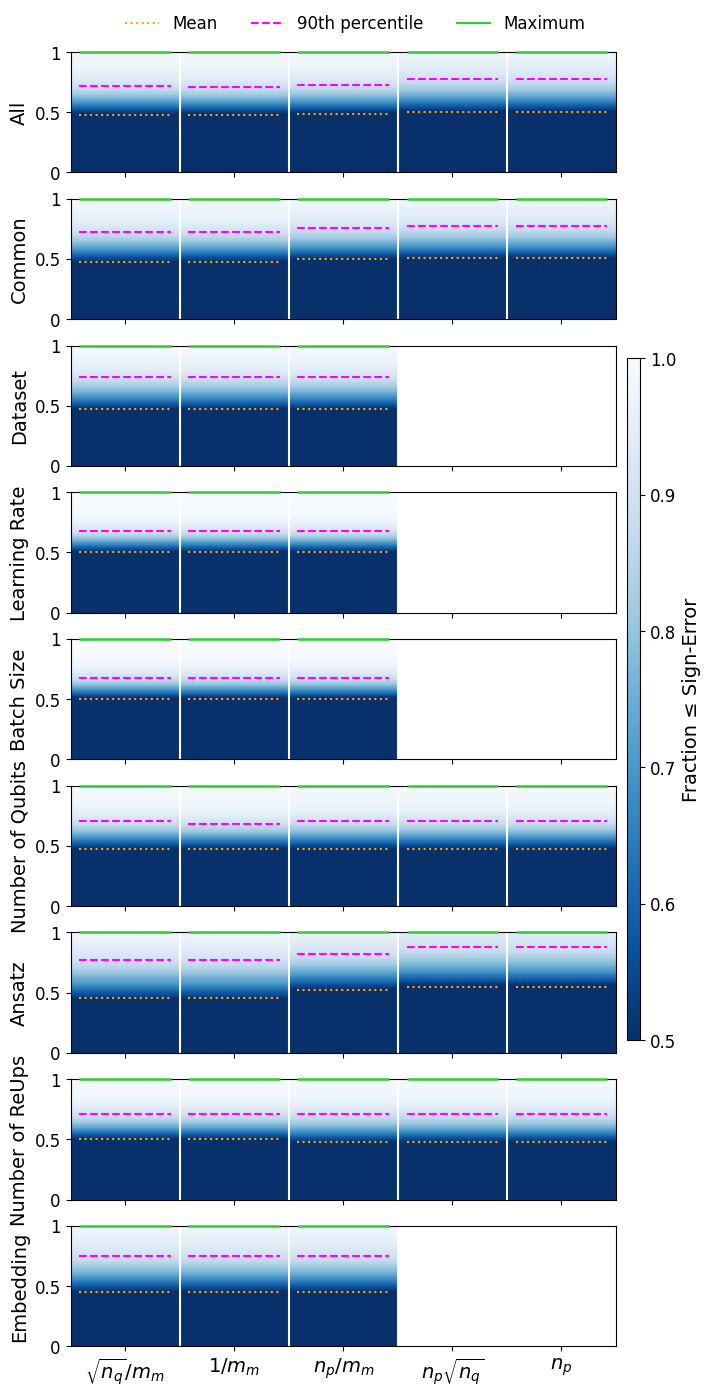

In [5]:
with open('./se_test/hyperparam_se_lists.json', 'r') as f:
    hyperparameter_se_lists = json.load(f)

labels = [r'$\sqrt{n_q}/m_m$', r'$1/m_m$', r'$n_p/m_m$', r'$n_p\sqrt{n_q}$', r'$n_p$']

se_lists = []
for cmi in range(5):
    se_list = np.load('./se_test/cm_{}_se_list.npy'.format(cmi))
    se_lists.append(se_list)

errors = {k : {} for k in hyperparameter_se_lists['0'].keys()}
errors['All'] = {}
for cmi, l in enumerate(labels):
    errors['All'][l] = se_lists[cmi]
    for k in hyperparameter_se_lists['0'].keys():
        errors[k][l] = hyperparameter_se_lists[str(cmi)][k]
errors['Common'] = errors.pop('common')
order = ['All', 'Common', 'Dataset', 'Learning Rate', 'Batch Size', 'Number of Qubits', 'Ansatz','Number of ReUps', 'Embedding']
fig, axes = plot_sign_error_cdf_bars(errors, subset_order=order, measure_order=labels)

In [6]:
for l in labels:
    values = errors['Common'][l]
    print(l, np.mean(values), np.quantile(values, 0.90), np.max(values))

$\sqrt{n_q}/m_m$ 0.4786597037516126 0.7274230567209818 1.0000000000000004
$1/m_m$ 0.4783445551826219 0.7225299824822902 1.0000000000000004
$n_p/m_m$ 0.4961557590902638 0.7531256230798341 1.0000000000000004
$n_p\sqrt{n_q}$ 0.5038129914734341 0.7724264309735254 1.0000000000000004
$n_p$ 0.5038129914734341 0.7724264309735254 1.0000000000000004


In [7]:
def plot_sign_error_cdf_bars(
    errors,
    subset_order=None,
    measure_order=None,
    view="summary",
    figsize=None,
    fontsize=9,
    annotate=True,
):
    """
    errors[subset][measure]: 1D array of environment-level sign errors.

    view="summary": heatmap of 90th-percentile sign errors.
    view="ecdf":    full ECDF bars with mean, 90th percentile, and maximum.

    Returns
    -------
    fig, axes
        axes is always a 1D array.
    """
    if view not in {"summary", "ecdf"}:
        raise ValueError("view must be 'summary' or 'ecdf'")

    if subset_order is None:
        subset_order = list(errors)

    # Clean arrays once. Missing/empty entries remain unavailable.
    values = {}
    measures = list(errors[subset_order[0]]) if measure_order is None else list(measure_order)

    for subset in subset_order:
        for measure in measures:
            x = np.asarray(
                errors[subset].get(measure, []), dtype=float
            ).ravel()
            x = np.sort(x[np.isfinite(x)])
            #if np.any((x < 0) | (x > 1)):
            #    raise ValueError(f"Sign errors outside [0, 1]: {subset}, {measure}")
            values[subset, measure] = x

    # Use the primary criterion to order columns; reuse for both figures.
    if measure_order is None:
        reference = "All" if "All" in subset_order else subset_order[0]
        measures.sort(
            key=lambda m: (
                np.quantile(values[reference, m], 0.90)
                if len(values[reference, m]) else np.inf
            )
        )

    n_rows, n_cols = len(subset_order), len(measures)

    if view == "summary":
        # Nine rows occupy approximately 4.4 inches vertically.
        if figsize is None:
            figsize = (max(6.5, 0.55 * n_cols + 2), 0.36 * n_rows + 1.2)

        fig, ax = plt.subplots(figsize=figsize, layout="constrained")
        axes = np.array([ax])

        q90 = np.full((n_rows, n_cols), np.nan)
        for row, subset in enumerate(subset_order):
            for col, measure in enumerate(measures):
                x = values[subset, measure]
                if len(x):
                    q90[row, col] = np.quantile(x, 0.90)

        cmap = plt.get_cmap("Blues").copy()
        cmap.set_bad("#eeeeee")
        vmin, vmax = 0.5, 1.0  # choose limits covering your actual values

        im = ax.imshow(
            np.ma.masked_invalid(q90),
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
            aspect="auto",
            interpolation="nearest",
        )

        ax.set_xticks(np.arange(n_cols), measures,
                      ha="center", va="top", fontsize=fontsize)
        ax.set_yticks(np.arange(n_rows), subset_order, fontsize=fontsize)

        # Fine white cell boundaries.
        ax.set_xticks(np.arange(n_cols + 1) - 0.5, minor=True)
        ax.set_yticks(np.arange(n_rows + 1) - 0.5, minor=True)
        ax.grid(which="minor", color="white", linewidth=1)
        ax.tick_params(which="both", length=0)

        if annotate:
            for row in range(n_rows):
                for col in range(n_cols):
                    value = q90[row, col]
                    scaled = (value - vmin) / (vmax - vmin)
                    text_color = "white" if scaled >= 0.65 else "#222222"
                    ax.text(
                        col, row,
                        f"{value:.2f}" if np.isfinite(value) else "—",
                        ha="center", va="center",
                        fontsize=fontsize - 1,
                        color=text_color if value >= 0.65 else "#222222",
                    )

        for spine in ax.spines.values():
            spine.set_visible(False)

        cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02, aspect=35)
        cbar.set_label("90th-percentile sign-error", fontsize=fontsize)
        cbar.ax.tick_params(labelsize=fontsize - 1)

    else:
        if figsize is None:
            figsize = (max(7, 0.65 * n_cols + 2), 1.05 * n_rows + 1.2)

        fig, axes = plt.subplots(
            n_rows, 1, figsize=figsize,
            sharex=True, sharey=True,
            squeeze=False, layout="constrained",
        )
        axes = axes[:, 0]
        thresholds = np.linspace(0, 1, 301)

        cmap = plt.get_cmap("Blues_r").copy()
        cmap.set_bad("#eeeeee")

        for ax, subset in zip(axes, subset_order):
            image = np.full((len(thresholds), n_cols), np.nan)

            for col, measure in enumerate(measures):
                x = values[subset, measure]
                if len(x):
                    image[:, col] = (
                        np.searchsorted(x, thresholds, side="right") / len(x)
                    )

            im = ax.imshow(
                np.ma.masked_invalid(image),
                origin="lower", extent=(0, n_cols, 0, 1),
                aspect="auto", interpolation="nearest",
                cmap=cmap, vmin=0.5, vmax=1,
            )

            ax.vlines(np.arange(1, n_cols), 0, 1,
                      colors="white", linewidth=1.2)

            for col, measure in enumerate(measures):
                x = values[subset, measure]
                if not len(x):
                    continue

                for statistic, color, linestyle in [
                    (np.mean(x), "orange", ":"),
                    (np.quantile(x, 0.90), "magenta", "--"),
                    (np.max(x), "limegreen", "-"),
                ]:
                    ax.hlines(
                        statistic, col + 0.08, col + 0.92,
                        color=color, linestyle=linestyle,
                        linewidth=1.5, zorder=5, clip_on=False,
                    )

            ax.set_ylabel(subset, fontsize=fontsize)
            ax.set_ylim(0, 1)
            ax.set_yticks([0, 0.5, 1])
            ax.tick_params(axis="y", labelsize=fontsize - 1)
            ax.spines[["top", "right"]].set_visible(False)

        axes[-1].set_xticks(np.arange(n_cols) + 0.5, measures,
                           rotation=40, ha="right", fontsize=fontsize)

        handles = [
            Line2D([], [], color="orange", linestyle=":", label="Mean"),
            Line2D([], [], color="magenta", linestyle="--",
                   label="90th percentile"),
            Line2D([], [], color="limegreen", label="Maximum"),
        ]
        fig.legend(
            handles=handles, loc="outside upper center",
            ncol=3, frameon=False, fontsize=fontsize,
        )

        cbar = fig.colorbar(
            im, ax=axes.tolist(),
            shrink=0.85, aspect=70, fraction=0.025, pad=0.02,
        )
        cbar.set_label("Fraction of environments ≤ sign error",
                       fontsize=fontsize)
        cbar.ax.tick_params(labelsize=fontsize - 1)

    return fig, axes

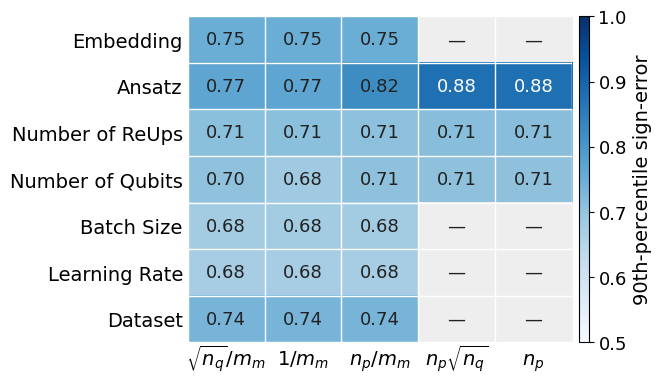

In [8]:
with open('./se_test/hyperparam_se_lists.json', 'r') as f:
    hyperparameter_se_lists = json.load(f)

labels = [r'$\sqrt{n_q}/m_m$', r'$1/m_m$', r'$n_p/m_m$', r'$n_p\sqrt{n_q}$', r'$n_p$']

se_lists = []
for cmi in range(5):
    se_list = np.load('./se_test/cm_{}_se_list.npy'.format(cmi))
    se_lists.append(se_list)

errors = {k : {} for k in hyperparameter_se_lists['0'].keys()}
errors.pop('common')
for cmi, l in enumerate(labels):
    for k in hyperparameter_se_lists['0'].keys():
        if k != 'common':
            errors[k][l] = hyperparameter_se_lists[str(cmi)][k]

fig, axes = plot_sign_error_cdf_bars(
    errors,
    subset_order=None,
    measure_order=labels,
    view="summary",
    figsize=None,
    fontsize=14,
    annotate=True
)
ax = axes[0]
ax.set_xticks(np.arange(len(labels)), labels)

for label in ax.get_xticklabels():
    label.set_rotation(0)
    label.set_horizontalalignment("center")
    label.set_verticalalignment("baseline")

ax.tick_params(axis="x", pad=16)

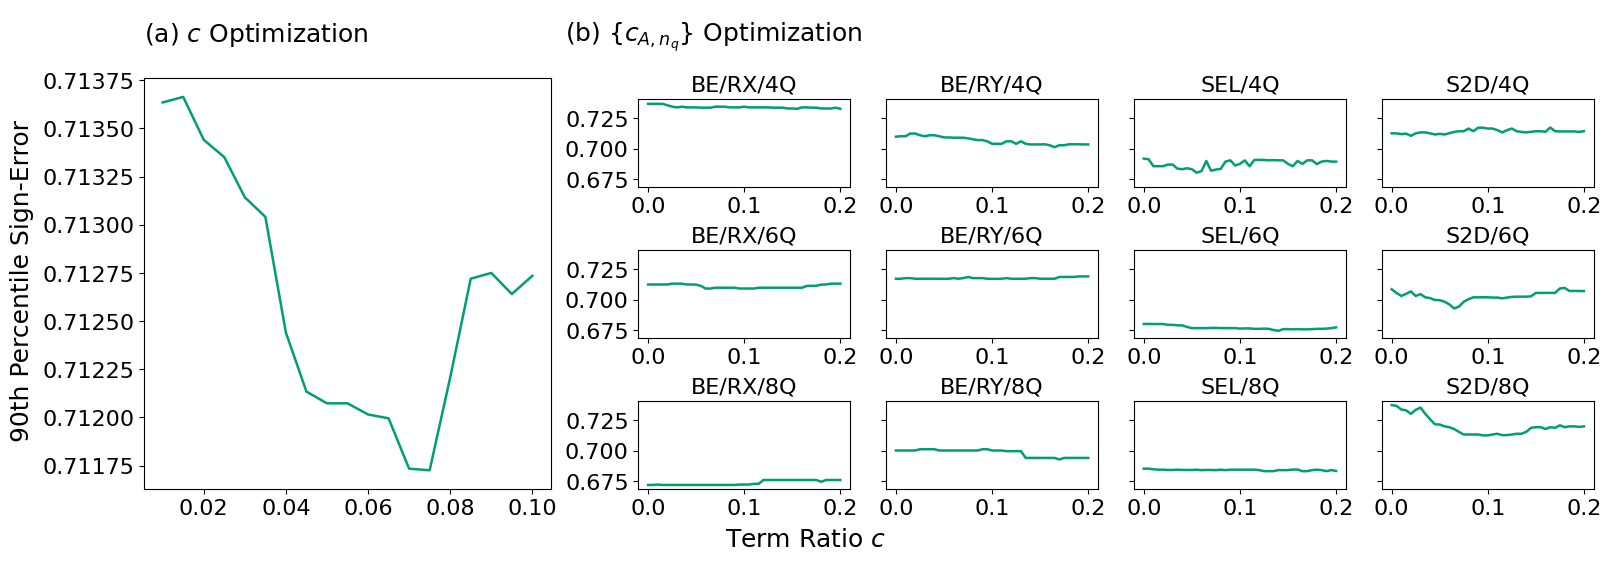

In [11]:
linecolor = "#009E73"
linewidth=1.8
large_font_size = 18
medium_font_size = 16
fig = plt.figure(figsize=(16, 5.5), layout="constrained")

# Two unequal-width panels, plus a caption row.
outer = fig.add_gridspec(
    1, 2,
    width_ratios=[1, 2],    # customize relative panel widths
    wspace=0.10,
)

# Right panel: heading above the 3 × 2 subplot grid.
right_panel = outer[0, 1].subgridspec(
    2, 1,
    height_ratios=[0.12, 1],
    hspace=0.05,
)

right_title_ax = fig.add_subplot(right_panel[0, 0])
right_title_ax.set_axis_off()
right_title_ax.text(
    0, 0.5,
    r"(b) $\{c_{A,n_q}\}$ Optimization",
    ha="left", va="center", fontsize=large_font_size,
    transform=right_title_ax.transAxes,
)

left_panel = outer[0, 0].subgridspec(
    2, 1,
    height_ratios=[0.12, 1],
    hspace=0.05,
)

left_title_ax = fig.add_subplot(left_panel[0, 0])
left_title_ax.set_axis_off()
left_title_ax.text(
    0, 0.5,
    r"(a) $c$ Optimization",
    ha="left", va="center", fontsize=large_font_size,
    transform=left_title_ax.transAxes,
)

# Panel (a): one plot.
ax_left = fig.add_subplot(left_panel[1, 0])

# Panel (b): six plots.
right_grid = right_panel[1, 0].subgridspec(
    3, 4,
    wspace=0.05,
    hspace=0.05,
)
axes_right = []
for row in range(3):
    for col in range(4):
        ax = fig.add_subplot(
            right_grid[row, col],
            sharey=axes_right[0] if axes_right else None,
        )
        axes_right.append(ax)
# Plot Panel (a)

cs = np.linspace(0.01, 0.1, 19)
se_lists = [np.load('./se_test/composite_measure_{}c_se_list.npy'.format('{:.2e}'.format(c))) for c in cs]
ax_left.plot(cs, [np.percentile(se_list, 90) for se_list in se_lists], color = linecolor, linewidth = linewidth)

# Plot Panel (b)
with open('./se_test/c_gridsearch_results.json', 'r') as f:
    c_gridsearch_results = json.load(f)

ABBREVIATION = {'BasicEntanglerLayers/RX': 'BE/RX',
                'BasicEntanglerLayers/RY': 'BE/RY',
                'StronglyEntanglingLayers/1L': 'SEL',
                'SimplifiedTwoDesign/1L': 'S2D'}

cs = np.linspace(0, 0.2, 41)
for data_idx, setting_name in enumerate(c_gridsearch_results.keys()):
    axes_right[data_idx].plot(cs, [np.percentile(se_list, 90) for se_list in [c_gridsearch_results[setting_name][str(c)] for c in cs]], color = linecolor, linewidth = linewidth)
    num_qubits = int(setting_name.split('_')[1][:-1])
    ansatz = setting_name.split('_')[0]
    axes_right[data_idx].set_title(ABBREVIATION[ansatz] + '/{}Q'.format(num_qubits), fontsize = medium_font_size)

for ax in [ax_left, *axes_right]:
    ax.tick_params(axis="both", which="both", labelsize=medium_font_size)

axes_right[0].yaxis.set_major_locator(MaxNLocator(nbins=3))
for i, ax in enumerate(axes_right):
    ax.tick_params(axis="y", labelsize=medium_font_size, labelleft=(i % 4 == 0))

fig.supxlabel(r'Term Ratio $c$', fontsize = large_font_size)
fig.supylabel('90th Percentile Sign-Error', fontsize = large_font_size)

plt.show()